<a href="https://colab.research.google.com/github/Mohamed-ktari/advanced-signal/blob/main/TPSA_RLS_NLMS_Mohamed_Ktari.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [141]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter,firwin,fftconvolve
import librosa
import scipy.io as sio
import IPython.display as ipd
import time

In [142]:
N = 1000
np.random.seed(0)
x = np.random.randn(N)
h = np.array([1, 0.8, -0.3, 0.4])
d = lfilter(h, [1], x)

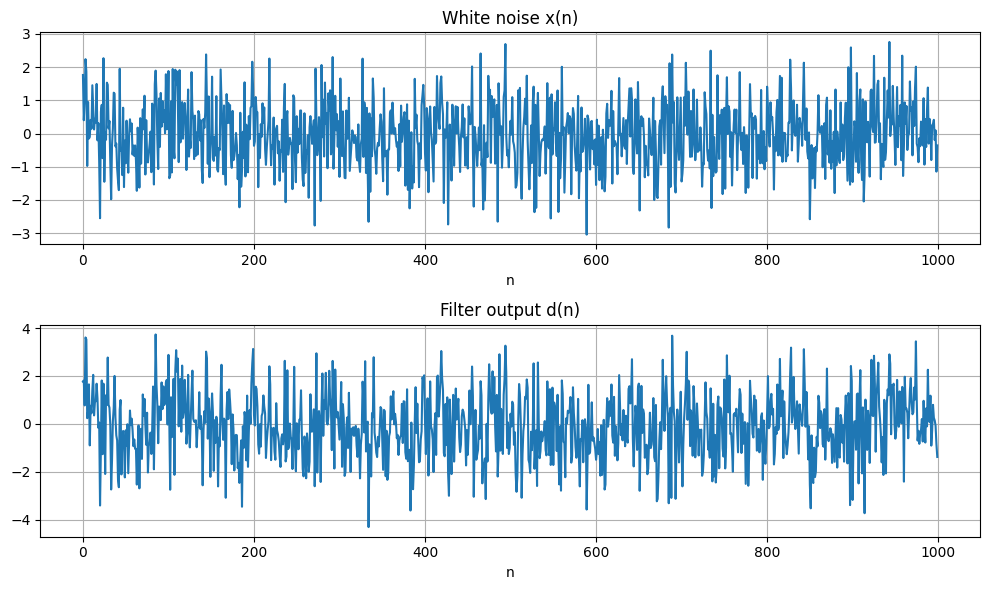

In [143]:
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(x)
plt.title("White noise x(n)")
plt.xlabel("n")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(d)
plt.title("Filter output d(n)")
plt.xlabel("n")
plt.grid(True)

plt.tight_layout()
plt.show()

In [144]:

def algoRLS(x, d, M, lam, delta=1e-2):

    x = np.asarray(x, dtype=float)
    d = np.asarray(d, dtype=float)
    N = len(x)

    w_hist = np.zeros((N, M))
    y = np.zeros(N)
    e = np.zeros(N)

    w = np.zeros(M)
    P = np.eye(M) / delta

    xp = np.concatenate((np.zeros(M - 1), x))

    for n in range(N):
        xn = xp[n:n + M][::-1]

        px = P @ xn
        sn = px / (lam + xn @ px)
        y[n] = w @ xn
        e[n] = d[n] - y[n]
        w = w + sn * e[n]
        P = (P - np.outer(sn, px)) / lam

        w_hist[n] = w

    return w_hist, y, e

In [145]:


M = 4
w, y, e = algoRLS(x, d, M, lam=0.99)

print("Final w :", w[-1])
print("True h  :", h)
print("Coefficient error ||w - h||² :", np.sum((w[-1] - h)**2))


Final w : [ 0.99999999  0.8        -0.3         0.4       ]
True h  : [ 1.   0.8 -0.3  0.4]
Coefficient error ||w - h||² : 4.5750290946385323e-17


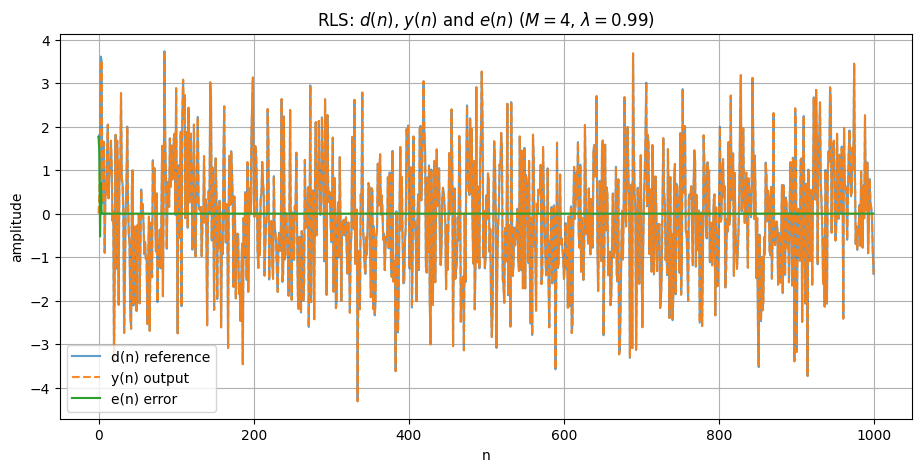

In [146]:
n = np.arange(N)
plt.figure(figsize=(11, 5))
plt.plot(n, d, label="d(n) reference", alpha=0.7)
plt.plot(n, y, "--", label="y(n) output", alpha=0.9)
plt.plot(n, e, label="e(n) error", linewidth=1.5)
plt.xlabel("n")
plt.ylabel("amplitude")
plt.title(r"RLS: $d(n)$, $y(n)$ and $e(n)$ ($M=4$, $\lambda=0.99$)")
plt.legend()
plt.grid(True)
plt.show()

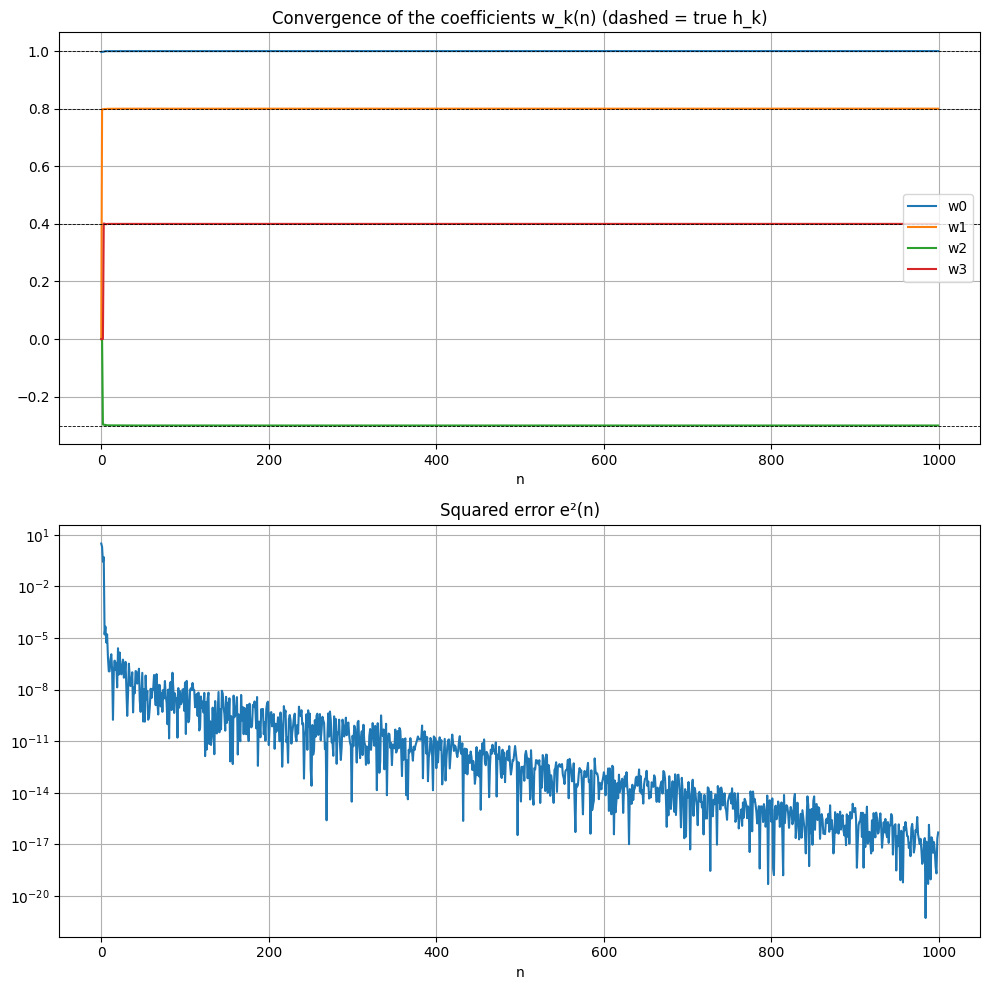

In [147]:
fig, ax = plt.subplots(2, 1, figsize=(10, 10))
# the coefficients
ax[0].plot(w)
for k, hk in enumerate(h):
    ax[0].axhline(hk, color='k', linestyle='--', linewidth=0.6)
ax[0].set_title("Convergence of the coefficients w_k(n) (dashed = true h_k)")
ax[0].legend([f"w{k}" for k in range(M)], loc="right")
ax[0].set_xlabel("n"); ax[0].grid(True)

#error
ax[1].semilogy(e**2)
ax[1].set_title("Squared error e²(n)")
ax[1].set_xlabel("n"); ax[1].grid(True)

plt.tight_layout()
plt.show()

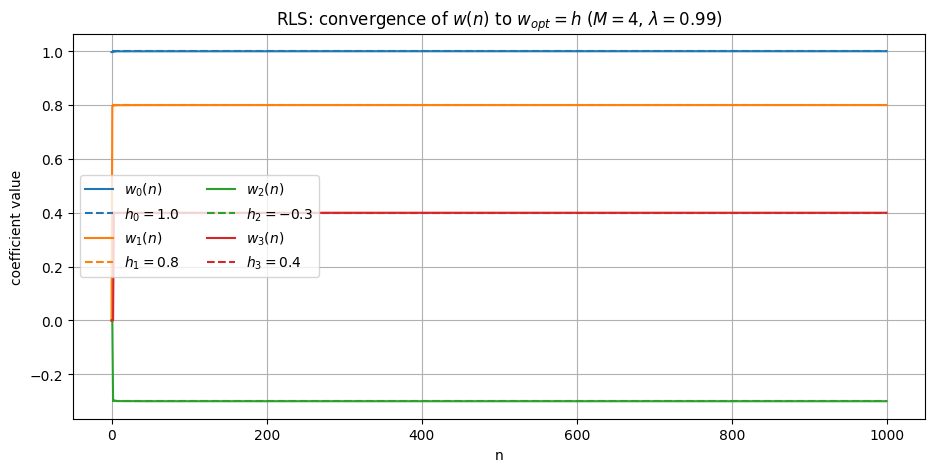

In [148]:
n = np.arange(N)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

plt.figure(figsize=(11, 5))
for i in range(M):
    plt.plot(n, w[:, i], color=colors[i], label=rf"$w_{i}(n)$")
    plt.hlines(h[i], 0, N - 1, colors=colors[i], linestyles="--",
               label=rf"$h_{i}={h[i]}$")
plt.xlabel("n")
plt.ylabel("coefficient value")
plt.title(r"RLS: convergence of $w(n)$ to $w_{opt}=h$ ($M=4$, $\lambda=0.99$)")
plt.legend(ncol=2)
plt.grid(True)
plt.show()

[0.99682873 0.99740284 0.99692881 0.99823955 0.99848498 0.99969431
 0.9996775  0.99937035 0.99936109 0.99936542 0.9993695  0.99945431
 0.99947908 0.99948678 0.99948667 0.99948659 0.99955219 0.99953535
 0.99953501 0.99954334 0.99971895 0.99970615 0.99974998 0.9997542
 0.99977562 0.99975341 0.99975549 0.9997522  0.99976839 0.99979477]


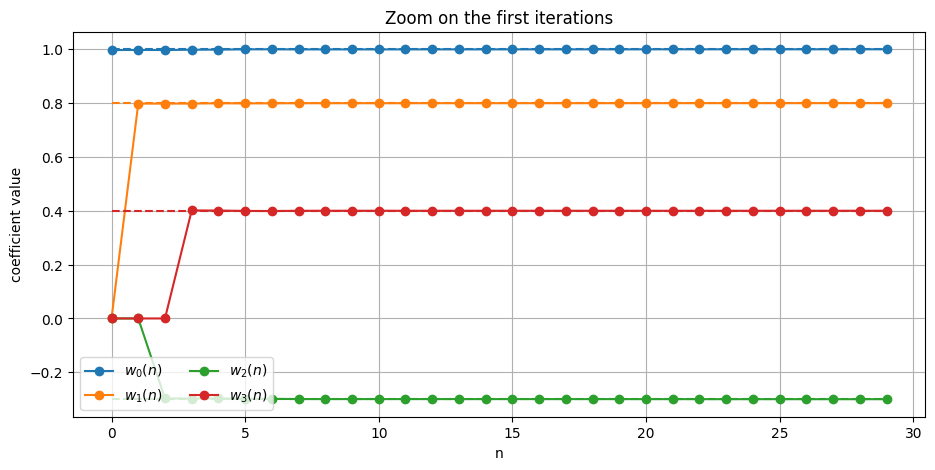

In [149]:
K = 30
plt.figure(figsize=(11, 5))
for i in range(M):
    plt.plot(n[:K], w[:K, i], "o-", color=colors[i], label=rf"$w_{i}(n)$")
    if(i==0):
      print(w[:K,i])
    plt.hlines(h[i], 0, K - 1, colors=colors[i], linestyles="--")
plt.xlabel("n")
plt.ylabel("coefficient value")
plt.title("Zoom on the first iterations")
plt.legend(ncol=2)
plt.grid(True)
plt.show()

In [150]:
# Parameters
fc = 0.5
orders = [5, 10, 15]
lams = [0.5, 0.7, 0.99]

In [151]:
def run(P, lam):
    h = firwin(P + 1, fc)
    d = lfilter(h, [1], x)
    return algoRLS(x, d, P + 1, lam), d, h

In [152]:
def plot_case(ax, d, y, e, title, K=None, ylim=(-5, 5)):
    if K is not None:
        d, y, e = d[:K], y[:K], e[:K]
    n = np.arange(len(d))
    mk = "o" if K is not None else None
    ax.plot(n, d, marker=mk, ms=3, label="d(n)")
    ax.plot(n, y, '--', marker=mk, ms=3, label="y(n)")
    ax.plot(n, e, marker=mk, ms=3, label="e(n)")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylim(*ylim)
    ax.grid(True)
    ax.legend(loc="upper right")

In [153]:
def conv_time(e, thr, win=5):
    e_s = np.convolve(np.abs(e), np.ones(win)/win, mode="same")
    above = np.where(e_s > thr)[0]
    return above[-1] + 1 if len(above) else 0

In [154]:
def plot_with_zoom(configs, K=30, thr=0.3):
    fig, axs = plt.subplots(2, len(configs), figsize=(16, 8), sharey=True)
    for j, (P, lam) in enumerate(configs):
        (w, y, e), d, h = run(P, lam)
        tc = conv_time(e, thr)
        t = rf"$P={P}$, $\lambda={lam}$, $n_c={tc}$"
        plot_case(axs[0, j], d, y, e, t)
        plot_case(axs[1, j], d, y, e, t + f" (zoom, first {K})", K=K)
        for i in (0, 1):
            axs[i, j].axvline(tc, color="r", ls=":", label="convergence")
    plt.tight_layout()
    plt.show()

In [155]:
N = 500
np.random.seed(0)
x = np.random.randn(N)
sigma_v = 0.1
v = sigma_v * np.random.randn(N)

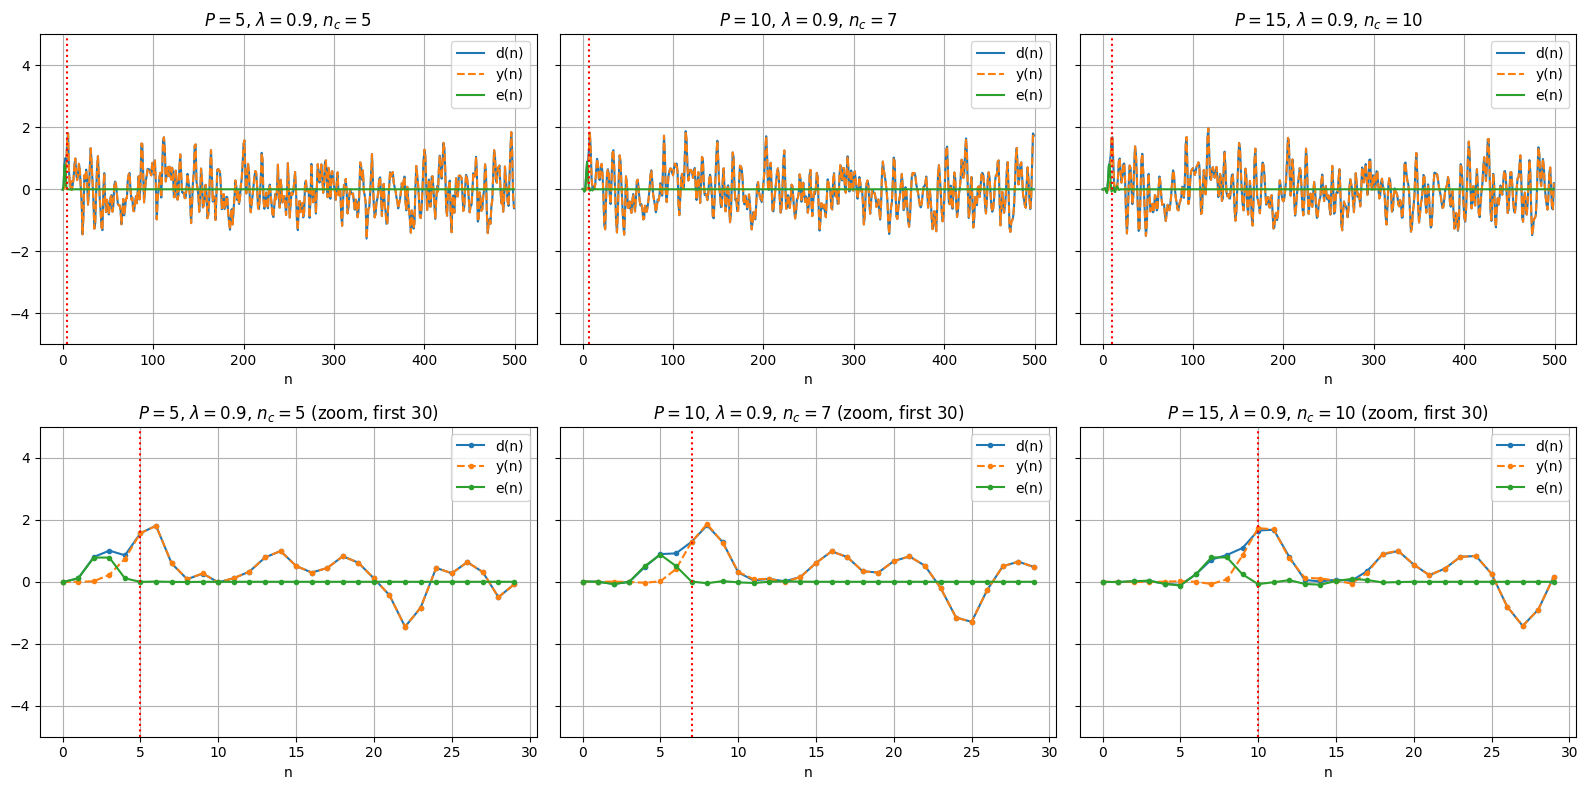

In [156]:
lam = 0.9
plot_with_zoom([(P, lam) for P in orders])

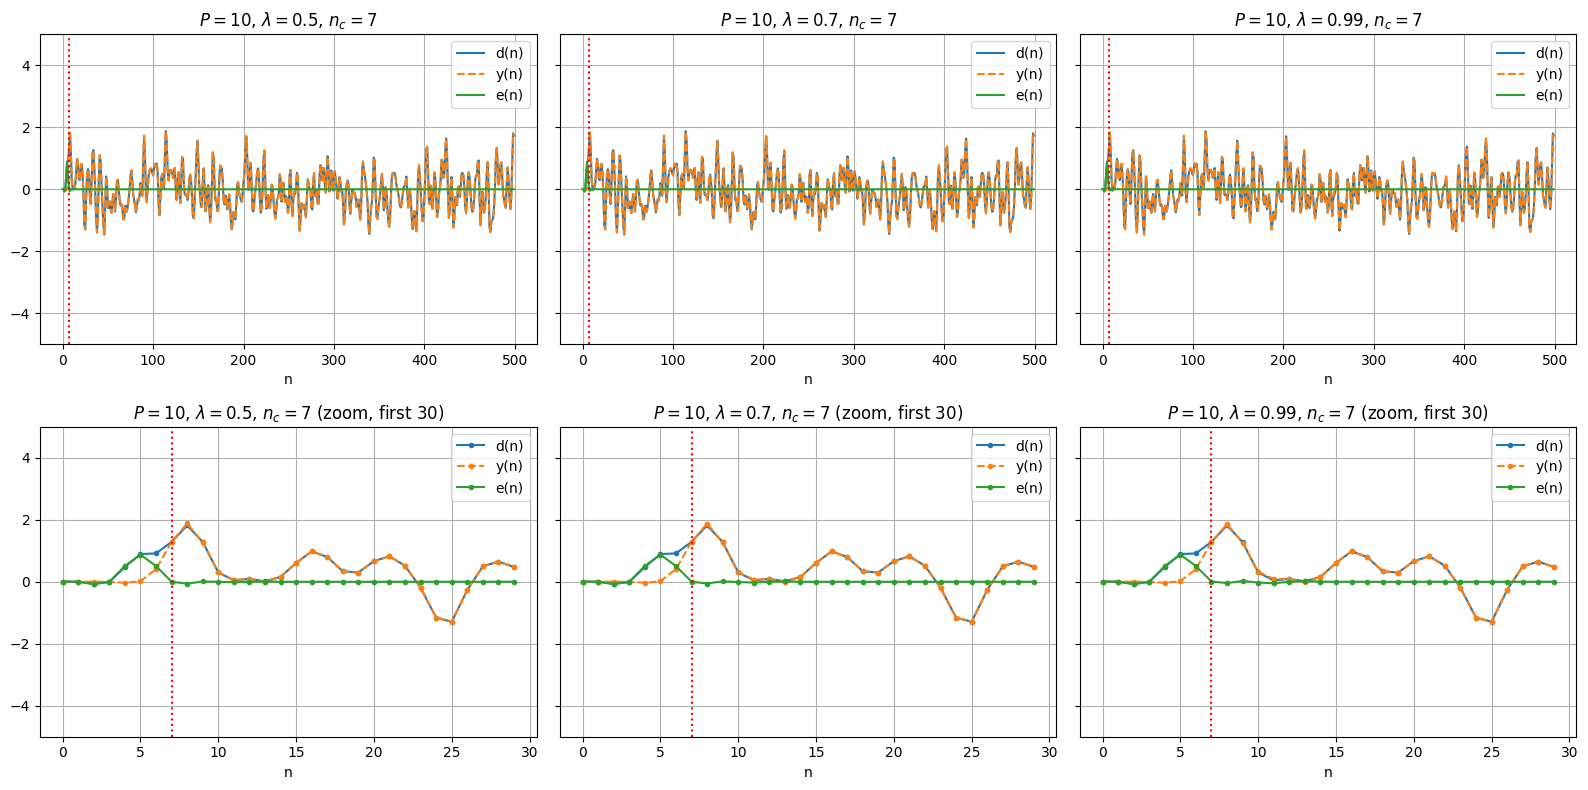

In [157]:
P = 10
plot_with_zoom([(P, lam) for lam in lams])

In [158]:

def algoLMS(x, d, M, mu):
    x = np.asarray(x, dtype=float)
    d = np.asarray(d, dtype=float)
    N = len(x)

    w = np.zeros(M)
    W = np.zeros((N, M))
    y = np.zeros(N)
    e = np.zeros(N)


    x_pad = np.concatenate((np.zeros(M - 1), x))

    for n in range(N):
        xn = x_pad[n:n + M][::-1]
        y[n] = w @ xn
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * xn
        W[n, :] = w

    return W, y, e

In [159]:


P = 10
M = P + 1
h = firwin(M, fc)
d = lfilter(h, [1], x) + v

t0 = time.perf_counter()
w_rls, y_rls, e_rls = algoRLS(x, d, M, lam=0.99)
t_rls = time.perf_counter() - t0
print(f"RLS time: {t_rls*1e3:.1f} ms")
mus = [0.005, 0.01, 0.05]
res_lms = {}
for mu in mus:
    t0 = time.perf_counter()
    W, y_l, e_l = algoLMS(x, d, M, mu)
    res_lms[mu] = (W, y_l, e_l, time.perf_counter() - t0)


for mu, r in res_lms.items():
    print(f"LMS mu={mu}: {r[3]*1e3:.1f} ms")

RLS time: 25.9 ms
LMS mu=0.005: 4.8 ms
LMS mu=0.01: 5.4 ms
LMS mu=0.05: 4.8 ms


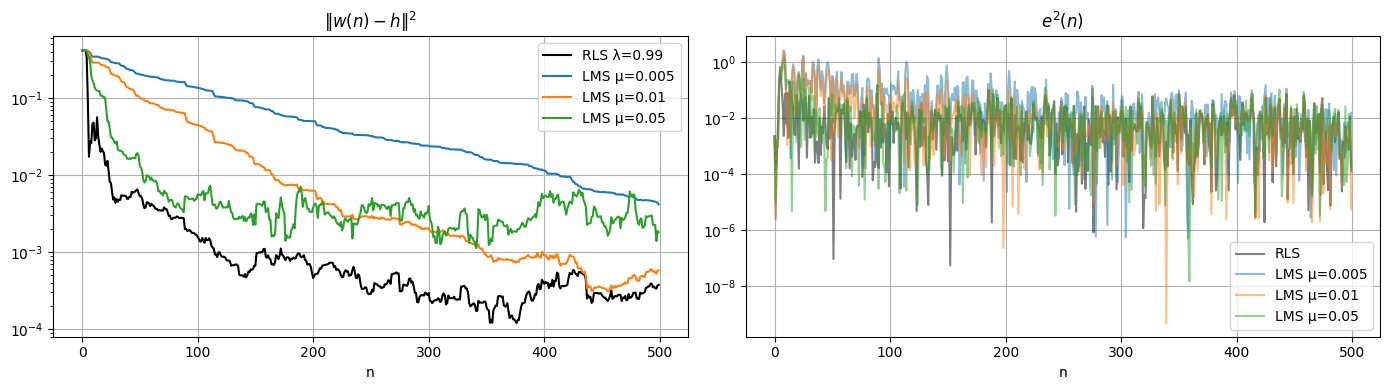

In [160]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

axs[0].semilogy(np.sum((w_rls - h)**2, axis=1), 'k', label="RLS λ=0.99")
for mu, (W, _, _, _) in res_lms.items():
    axs[0].semilogy(np.sum((W - h)**2, axis=1), label=f"LMS μ={mu}")
axs[0].set_title(r"$\|w(n)-h\|^2$"); axs[0].set_xlabel("n")

axs[1].semilogy(e_rls**2, 'k', alpha=0.5, label="RLS")
for mu, (_, _, e_l, _) in res_lms.items():
    axs[1].semilogy(e_l**2, alpha=0.5, label=f"LMS μ={mu}")
axs[1].set_title(r"$e^2(n)$"); axs[1].set_xlabel("n")

for a in axs: a.grid(True); a.legend()
plt.tight_layout(); plt.show()

In [161]:
print("Algo          MSE_ss        ||w-h||^2_ss")
print(f"RLS 0.99      {np.mean(e_rls[-100:]**2):.3e}   {np.sum((w_rls[-1]-h)**2):.3e}")
for mu, (W, _, e_l, _) in res_lms.items():
    print(f"LMS mu={mu:<5} {np.mean(e_l[-100:]**2):.3e}   {np.sum((W[-1]-h)**2):.3e}")
print("Noise floor sigma_v^2 =", sigma_v**2)

Algo          MSE_ss        ||w-h||^2_ss
RLS 0.99      9.879e-03   3.759e-04
LMS mu=0.005 1.658e-02   4.178e-03
LMS mu=0.01  9.960e-03   5.784e-04
LMS mu=0.05  1.380e-02   1.821e-03
Noise floor sigma_v^2 = 0.010000000000000002


In [162]:
signal, Fs = librosa.load("Voix1.wav", sr=None)

In [163]:
print(f"Sampling Rate: {Fs} Hz")
print(f"Duration: {len(signal) / Fs:.2f} seconds")
print(f"Signal Shape: {signal.shape}")

Sampling Rate: 16000 Hz
Duration: 5.31 seconds
Signal Shape: (85000,)


In [164]:
ipd.Audio(signal, rate=Fs)

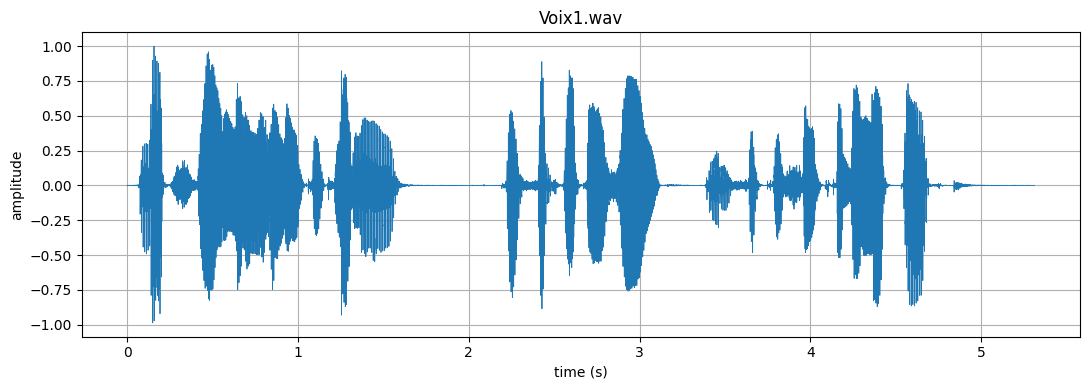

In [165]:
t = np.arange(len(signal)) / Fs

plt.figure(figsize=(11, 4))
plt.plot(t, signal, linewidth=0.6)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("Voix1.wav")
plt.grid(True)
plt.tight_layout()
plt.show()

In [166]:
np.random.seed(0)
N = len(signal)

b = np.random.randn(N)


order = 32
fc = 0.5
h = firwin(order + 1, fc)

bc = lfilter(h, [1], b)

print("h length        :", len(h))
print("var(b)          :", np.var(b))
print("var(h*b)        :", np.var(bc))
print("sum(h^2) (theory):", np.sum(h**2))

h length        : 33
var(b)          : 0.9933948736714349
var(h*b)        : 0.47770539121448663
sum(h^2) (theory): 0.4770298163718909


In [167]:
d = signal + bc

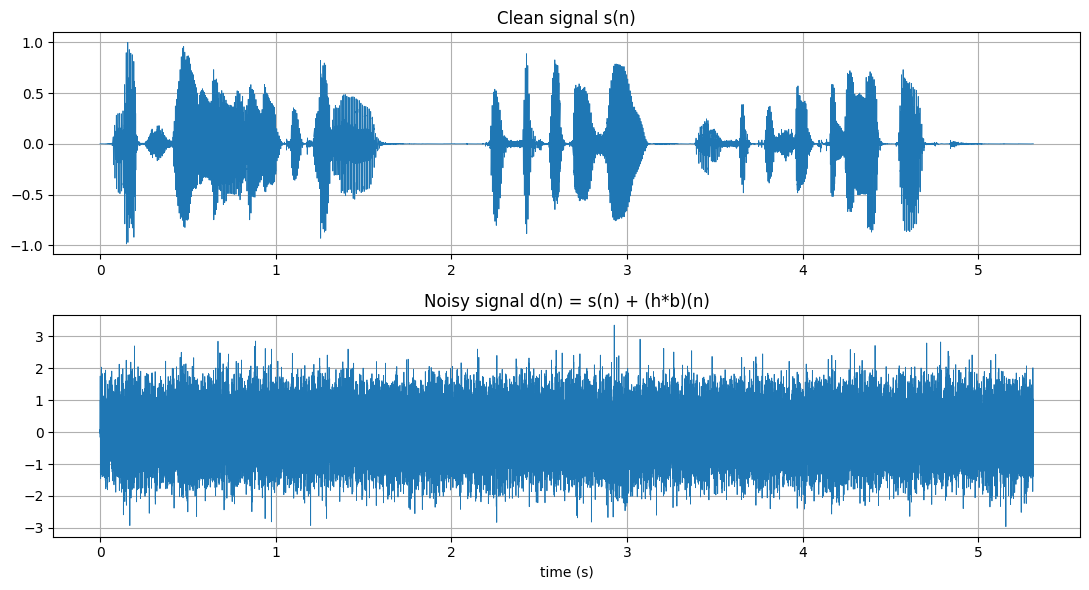

In [168]:
t = np.arange(N) / Fs

plt.figure(figsize=(11, 6))
plt.subplot(2, 1, 1)
plt.plot(t, signal, linewidth=0.6)
plt.title("Clean signal s(n)")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, d, linewidth=0.6)
plt.title("Noisy signal d(n) = s(n) + (h*b)(n)")
plt.xlabel("time (s)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [169]:
ipd.Audio(d, rate=Fs)

In [182]:


np.random.seed(0)
N = len(signal)
h = firwin(33, 0.5)
M = 33
lam = 1.0
sigmas = [0.1, 0.5, 1, 2, 5]
skip = 5000

Ps = np.mean(signal**2)
results = {}

print(" sigma   SNR_in(dB)   SNR_out(dB)   gain(dB)   time(s)")
for sigma in sigmas:
    b = sigma * np.random.randn(N)
    bc = lfilter(h, [1], b)
    d = signal + bc

    t0 = time.perf_counter()
    w, y, e = algoRLS(b, d, M, lam)
    dt = time.perf_counter() - t0
    w_final = w[-1].copy()
    del w

    snr_in  = 10 * np.log10(Ps / np.mean(bc**2))
    snr_out = 10 * np.log10(np.mean(signal[skip:]**2) /
                            np.mean((e[skip:] - signal[skip:])**2))
    results[sigma] = (d, e, w_final)
    print(f"{sigma:5.1f}   {snr_in:9.2f}   {snr_out:10.2f}   {snr_out - snr_in:8.2f}   {dt:6.2f}")

 sigma   SNR_in(dB)   SNR_out(dB)   gain(dB)   time(s)
  0.1        6.82      -101.44    -108.27     2.20
  0.5       -7.12       -58.97     -51.86     2.12
  1.0      -13.16       -79.50     -66.35     2.92
  2.0      -19.23       -74.68     -55.46     3.16
  5.0      -27.16       -62.82     -35.66     2.18


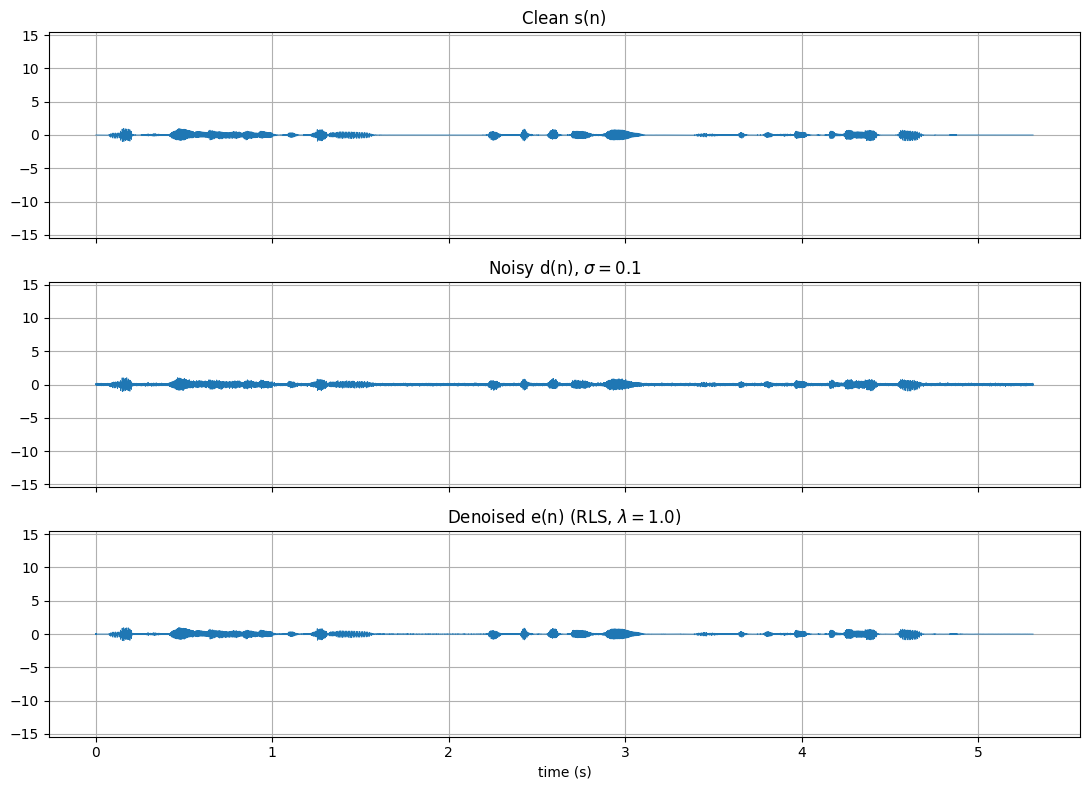

--- sigma = 0.1 ---
Clean:


Noisy:


Denoised:


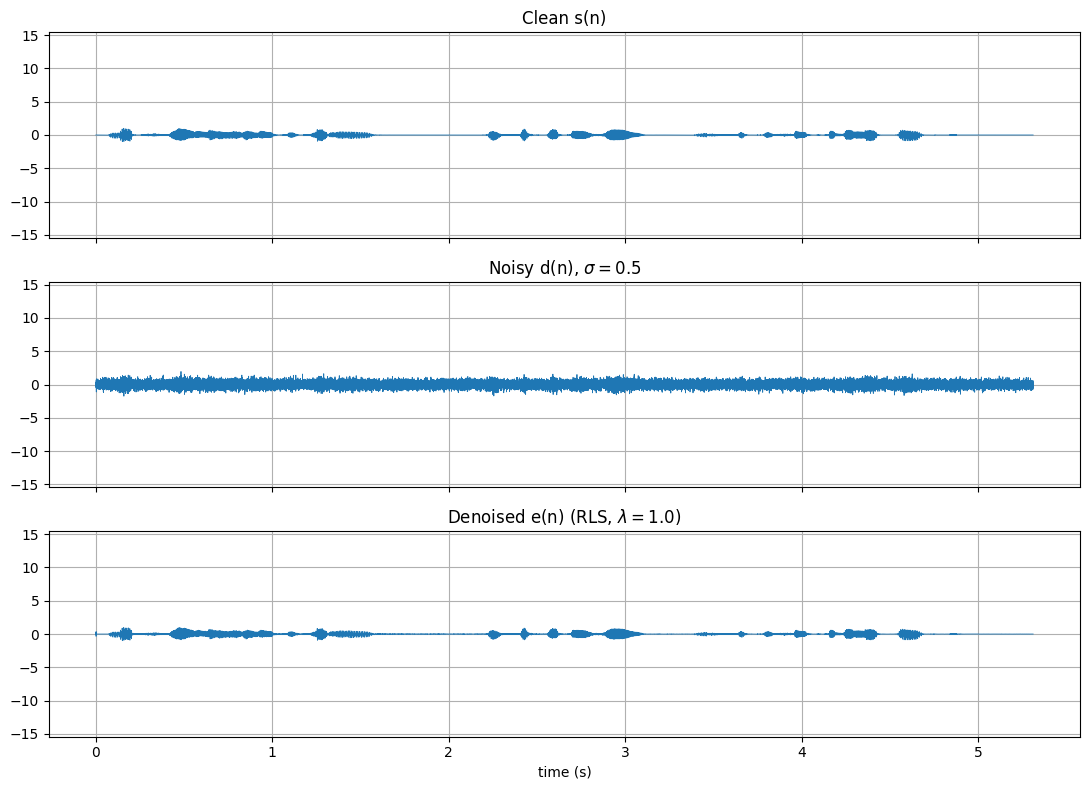

--- sigma = 0.5 ---
Clean:


Noisy:


Denoised:


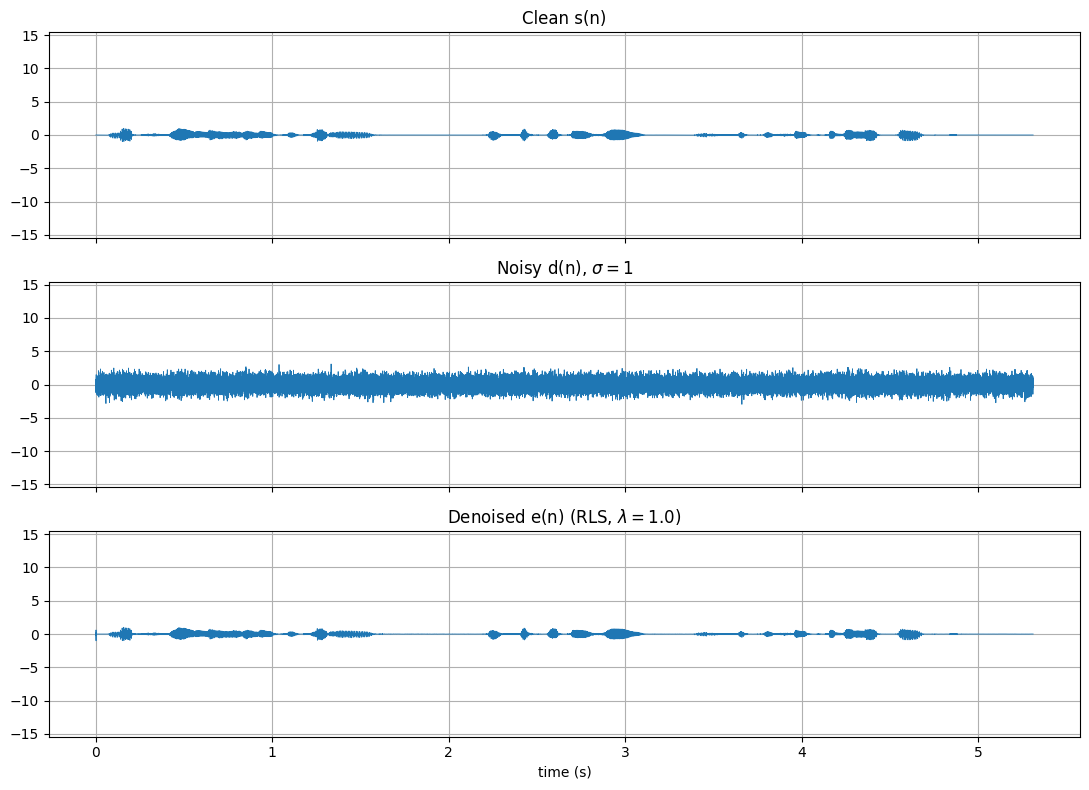

--- sigma = 1 ---
Clean:


Noisy:


Denoised:


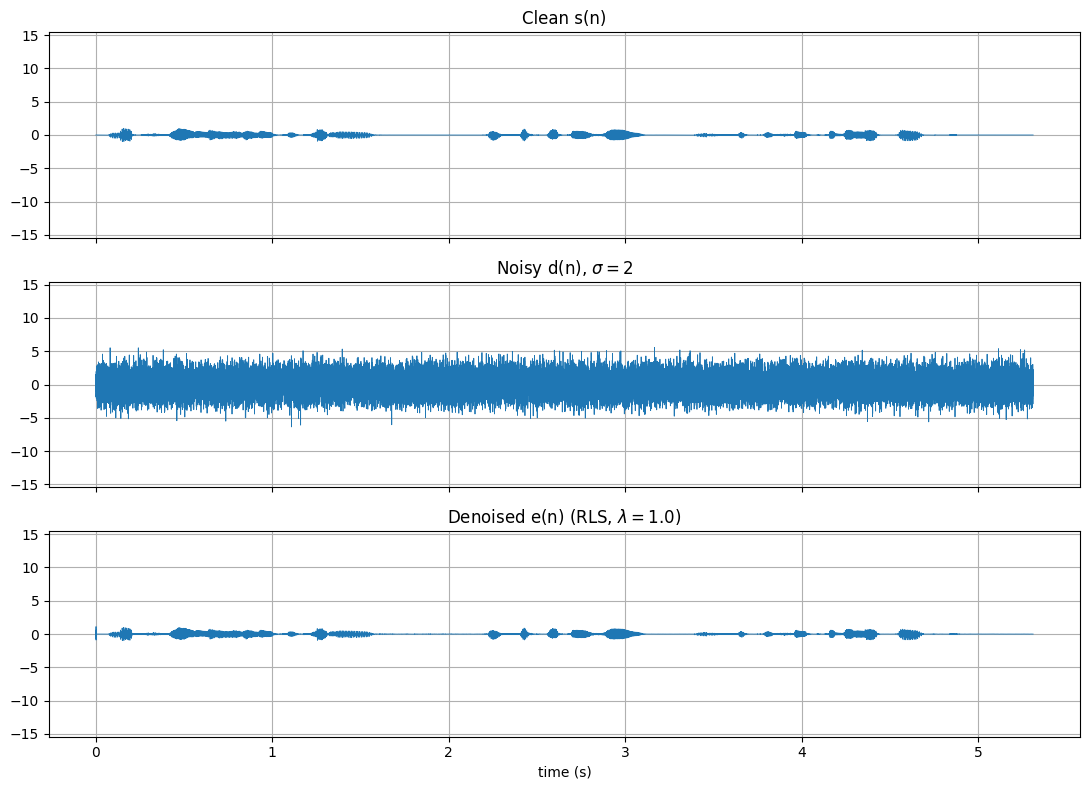

--- sigma = 2 ---
Clean:


Noisy:


Denoised:


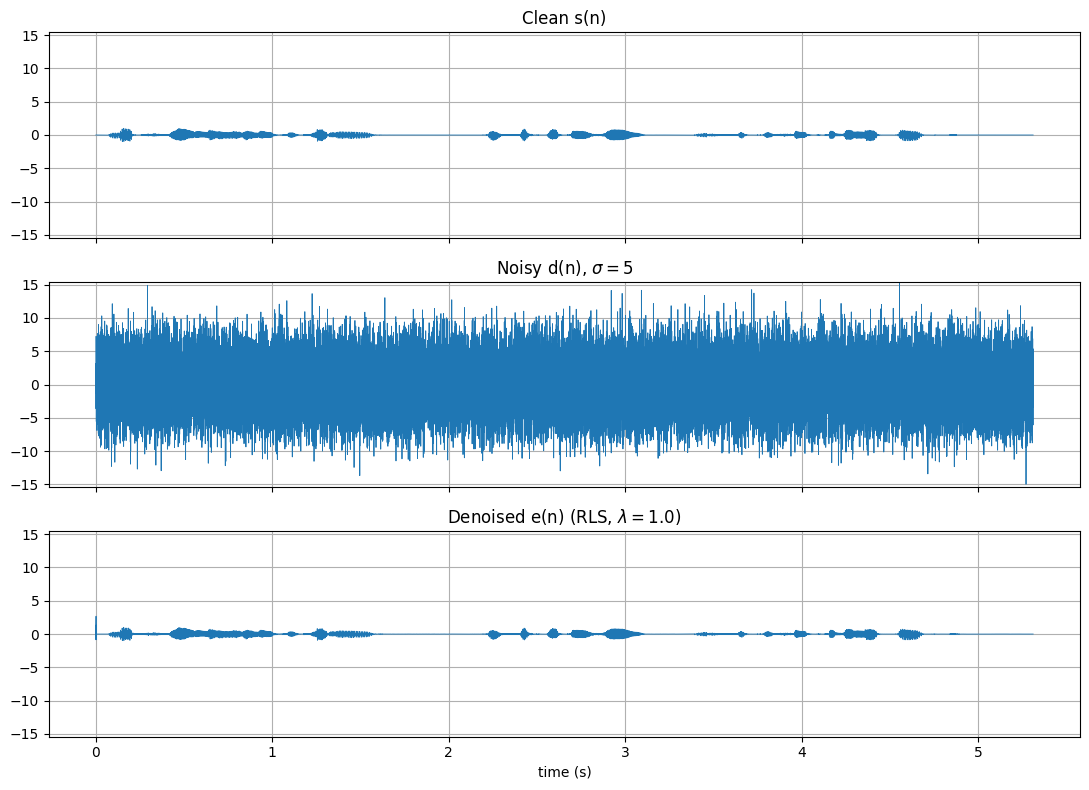

--- sigma = 5 ---
Clean:


Noisy:


Denoised:


In [188]:


t = np.arange(N) / Fs

ymax = max(np.max(np.abs(results[s][0])) for s in sigmas)

for sigma in sigmas:
    d, e, w_final = results[sigma]

    fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    axs[0].plot(t, signal, lw=0.6)
    axs[0].set_title("Clean s(n)")

    axs[1].plot(t, d, lw=0.6)
    axs[1].set_title(rf"Noisy d(n), $\sigma={sigma}$")

    axs[2].plot(t, e, lw=0.6)
    axs[2].set_title(rf"Denoised e(n) (RLS, $\lambda={lam}$)")
    axs[2].set_xlabel("time (s)")

    for ax in axs:
        ax.set_ylim(-ymax, ymax)
        ax.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"--- sigma = {sigma} ---")
    print("Clean:");    ipd.display(ipd.Audio(signal, rate=Fs))
    print("Noisy:");    ipd.display(ipd.Audio(d, rate=Fs))
    print("Denoised:"); ipd.display(ipd.Audio(e, rate=Fs))

In [175]:
def algoNLMS(x, d, M, mu, eps=1e-8):
    x = np.asarray(x, dtype=float)
    d = np.asarray(d, dtype=float)
    N = len(x)

    w = np.zeros(M)
    W = np.zeros((N, M))
    y = np.zeros(N)
    e = np.zeros(N)

    x_pad = np.concatenate((np.zeros(M - 1), x))

    for n in range(N):
        xn = x_pad[n:n + M][::-1]
        y[n] = w @ xn
        e[n] = d[n] - y[n]
        w = w + (mu / (xn @ xn + eps)) * e[n] * xn
        W[n, :] = w

    return W, y, e

In [190]:

N = 500
np.random.seed(0)
x = np.random.randn(N)
sigma_v = 0.1
v = sigma_v * np.random.randn(N)

fc = 0.5
orders = [5, 10, 15]
mus = [0.1, 0.5, 1.0]

def run_nlms(P, mu):
    h = firwin(P + 1, fc)
    d = lfilter(h, [1], x) + v
    W, y, e = algoNLMS(x, d, P + 1, mu)
    return (W, y, e), d, h

In [193]:
M = 4
h = np.array([1, 0.8, -0.3, 0.4])
d = lfilter(h, [1], x) + v

W, y, e = algoNLMS(x, d, M, mu=0.5)

print("Final w :", W[-1])
print("True h  :", h)
print("Coefficient error ||w - h||² :", np.sum((W[-1] - h)**2))

Final w : [ 1.01380367  0.82913626 -0.26634049  0.38679316]
True h  : [ 1.   0.8 -0.3  0.4]
Coefficient error ||w - h||² : 0.0023468463896116638


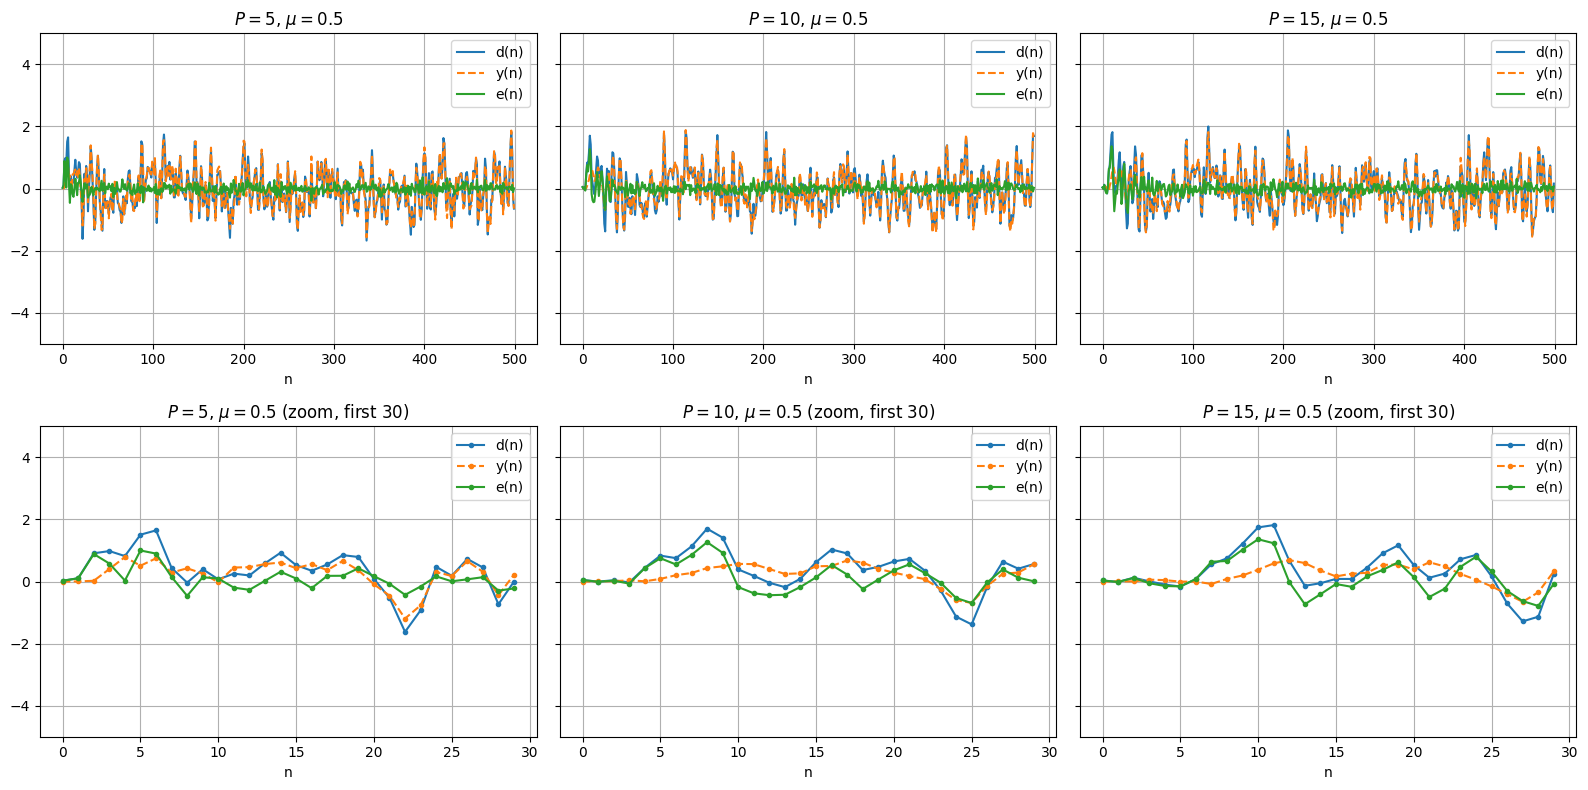

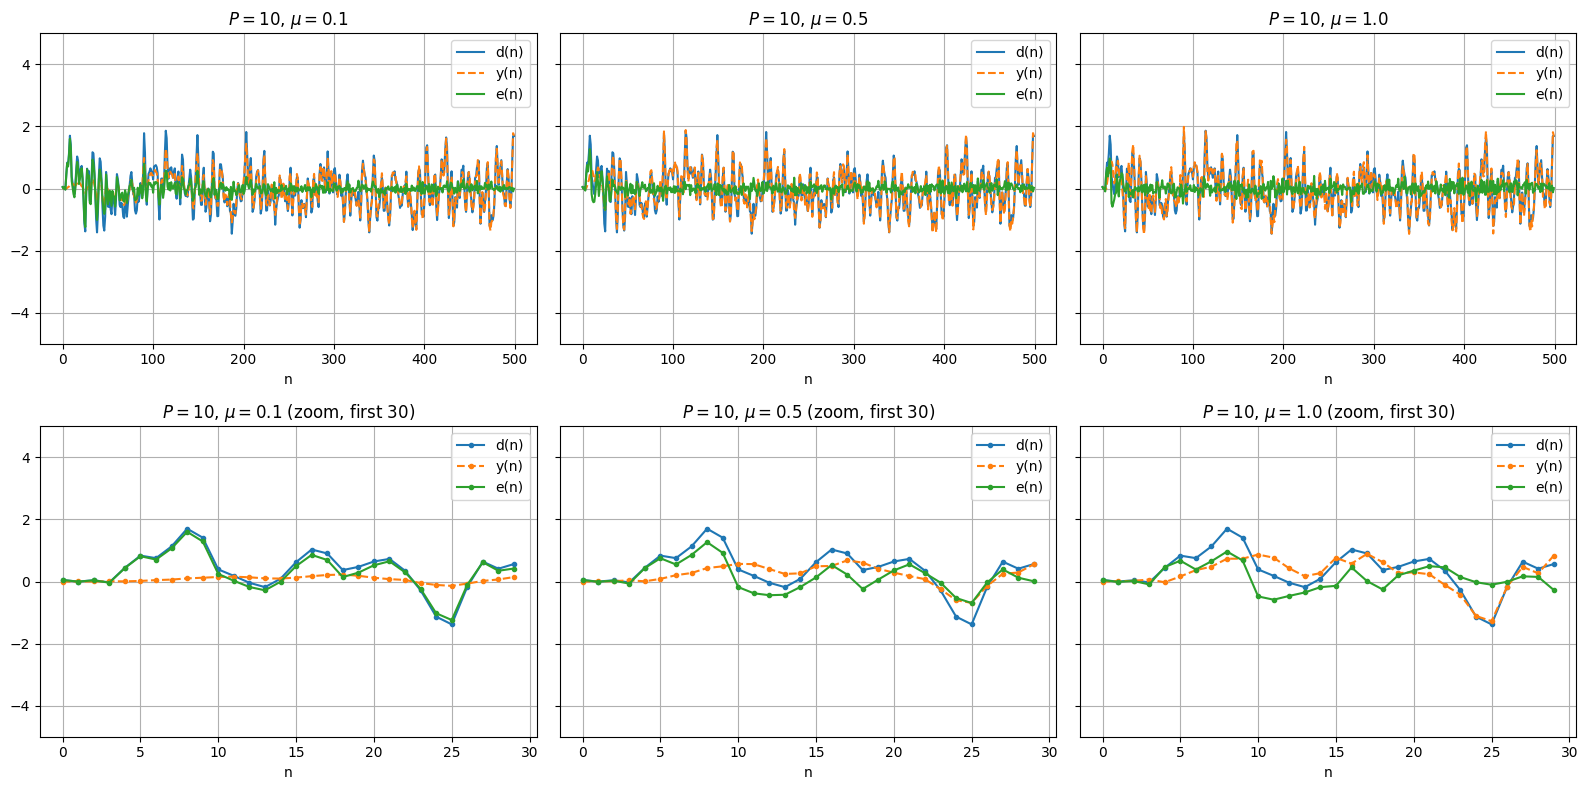

In [194]:
def plot_with_zoom_nlms(configs, K=30):
    fig, axs = plt.subplots(2, len(configs), figsize=(16, 8), sharey=True)
    for j, (P, mu) in enumerate(configs):
        (W, y, e), d, h = run_nlms(P, mu)
        t = rf"$P={P}$, $\mu={mu}$"
        plot_case(axs[0, j], d, y, e, t)
        plot_case(axs[1, j], d, y, e, t + f" (zoom, first {K})", K=K)
    plt.tight_layout(); plt.show()


plot_with_zoom_nlms([(P, 0.5) for P in orders])


plot_with_zoom_nlms([(10, mu) for mu in mus])